# Offline Basketball Video Inference with RF-DETR Small

**Feature:** Run offline RF-DETR Small inference on complete clips using the
available CUDA, MPS, or CPU device.

**Input:**

- Three local basketball videos,
- and the latest available trained RF-DETR Small checkpoint.

**Outputs** (saved in a fresh output directory for each video):

- Annotated MP4 video (review manually).
- Per-frame detections in JSONL format.
- Small processing summary.

## 1. Import helpers and resolve paths

In [1]:
from __future__ import annotations

import json
import os
from importlib.metadata import version
from itertools import islice
from pathlib import Path

import cv2
import supervision as sv
from detection_common import Device, configure_stdio_relative_path
from detection_common.utils.json_io import print_json, read_json, write_json
from detection_evaluation import (
    find_latest_path,
    read_run_protocol,
    read_training_record,
)
from IPython.display import Markdown, display
from PIL import Image

from rfdetr_pipeline.config import (
    DATA_ROOT,
    OUTPUT_ROOT,
    SUBPROJECT_ROOT,
    WORKSPACE_ROOT,
)
from rfdetr_pipeline.rfdetr import configure_caches, load_best_model
from rfdetr_pipeline.video_inference import run_video_inference

configure_stdio_relative_path(WORKSPACE_ROOT)
configure_caches(WORKSPACE_ROOT)


def relative_path(path: Path | str) -> str:
    """
    Format notebook output paths relative to the workspace root.
    """
    path = Path(path)
    if not path.is_absolute():
        return path.as_posix()
    return Path(os.path.relpath(path, WORKSPACE_ROOT)).as_posix()

## 2. Configure the videos and discover the latest checkpoint

`find_latest_path` selects by checkpoint modification time and skips runs
without `checkpoint_best_total.pth`. Set `CHECKPOINT_PATH` to an absolute path
to repeat a particular model selection. Paths displayed and saved in metadata
are relative to the workspace root; file operations use absolute paths.

In [2]:

RUNS_DIR = OUTPUT_ROOT / "runs" / "basketball"
CHECKPOINT_PATH = None
CONFIDENCE_THRESHOLD = 0.25
DEVICE = Device.auto_choose().value
MAX_FRAMES = None

VIDEO_DIR = DATA_ROOT / "sources/downloads/basketball_videos"
VIDEO_PATHS = [
    VIDEO_DIR / "basketball-uhd_4096_2160_30fps.mp4",
    VIDEO_DIR / "basketball_dribbling.webm",
    VIDEO_DIR / "basketball-nba_clip.mp4",
]
for video_path in VIDEO_PATHS:
    if not video_path.is_file():
        raise FileNotFoundError(video_path)

checkpoint_path = CHECKPOINT_PATH or find_latest_path(
    RUNS_DIR, "rfdetr_small*/checkpoint_best_total.pth"
)
if checkpoint_path is None:
    raise FileNotFoundError(f"No RF-DETR Small checkpoint found below {RUNS_DIR}")
checkpoint_path = Path(checkpoint_path).expanduser().resolve()

run_dir = checkpoint_path.parent

## 3. Check inputs and load the trained model once

Use a completed, full-dataset basketball run. The existing loader restores the
trained resolution and selected weights, including compiled weight names.
The loader disables AMP and compilation; the inference device is selected
independently of the saved training device (CUDA, then MPS, then CPU).

In [3]:
protocol = read_run_protocol(run_dir)
if protocol["model"] != "rfdetr_small" or protocol["logical_dataset"] != "basketball":
    raise ValueError(f"Unexpected model or dataset in {run_dir}")
if protocol["smoke_run"]:
    raise ValueError("Select a full-dataset training checkpoint")
training = read_training_record(run_dir)
if training["summary"]["status"] != "completed":
    raise ValueError(f"The selected training run is not complete: {run_dir}")
mapping = read_json(run_dir / "dataset_manifest.json")["category_mapping"]
if mapping["class_names"] != ["basketball"] or set(mapping["prediction_to_source"]) != {
    "0"
}:
    raise ValueError("Expected a single basketball category in the saved manifest")

category_id = int(mapping["prediction_to_source"]["0"])
print_json({
    "checkpoint_path": relative_path(checkpoint_path),
    "device": DEVICE,
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "max_frames": MAX_FRAMES,
    "category_id": category_id,
    "rfdetr": version("rfdetr"),
    "supervision": version("supervision"),
}, title="Inference configuration:")

for video_path in VIDEO_PATHS:
    video_info = sv.VideoInfo.from_video_path(str(video_path))
    print_json({
        "video_path": relative_path(video_path),
        "source_width": video_info.width,
        "source_height": video_info.height,
        "source_fps": video_info.fps,
        "reported_frames": video_info.total_frames,
    }, title=f"Video metadata: {video_path.name}")

model, checkpoint_metadata = load_best_model(run_dir, device=DEVICE)
print_json({
    **checkpoint_metadata,
    "checkpoint": relative_path(checkpoint_metadata["checkpoint"]),
    "source_checkpoint": relative_path(checkpoint_metadata["source_checkpoint"]),
}, title="Checkpoint metadata:")

Inference configuration:
{
  "category_id": 1,
  "checkpoint_path": "outputs/runs/basketball/rfdetr_small_20261106T124419/checkpoint_best_total.pth",
  "confidence_threshold": 0.25,
  "device": "mps",
  "max_frames": null,
  "rfdetr": "1.11.2",
  "supervision": "0.30.2"
}
Video metadata: basketball-uhd_4096_2160_30fps.mp4
{
  "reported_frames": 236,
  "source_fps": 30.0,
  "source_height": 2160,
  "source_width": 4096,
  "video_path": "data/sources/downloads/basketball_videos/basketball-uhd_4096_2160_30fps.mp4"
}
Video metadata: basketball_dribbling.webm
{
  "reported_frames": 1758,
  "source_fps": 29.97,
  "source_height": 540,
  "source_width": 960,
  "video_path": "data/sources/downloads/basketball_videos/basketball_dribbling.webm"
}
Video metadata: basketball-nba_clip.mp4
{
  "reported_frames": 555,
  "source_fps": 60.0,
  "source_height": 720,
  "source_width": 1280,
  "video_path": "data/sources/downloads/basketball_videos/basketball-nba_clip.mp4"
}


.conda/envs/object-detection-rfdetr/lib/python3.11/site-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
.conda/envs/object-detection-rfdetr/lib/python3.11/site-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
.conda/envs/object-detection-rfdetr/lib/python3.11/site-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-11-11 21:13:54] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-11-11 21:13:54] [WARNING] rf-detr - Using patch size 16 in

Checkpoint metadata:
{
  "best_epoch": 29,
  "checkpoint": "outputs/runs/basketball/rfdetr_small_20261106T124419/checkpoint_best_total.pth",
  "checkpoint_sha256": "85fc2abfa9fd2aa0964c7b355900711aae8f0c6185776f63bfefc597bd287c64",
  "parameters": 32012132,
  "selected_weights": "ema",
  "selection_metric": "validation AP50:95",
  "source_checkpoint": "outputs/runs/basketball/rfdetr_small_20261106T124419/checkpoint_best_ema.pth"
}


## 4. Process the full clips

- Predict from each frame's RGB view and retain basketball detections.
- Write one JSONL record per frame.
- Return a BGR frame with boxes and confidence labels.
- Keep empty-detection frames in the video and log.
- Use small input/output buffers to keep UHD frames from accumulating in memory.

Rerunning this cell creates a fresh output directory per video and preserves
prior runs. `MAX_FRAMES` applies separately to each video.

In [4]:
output_dirs = []
for video_path in VIDEO_PATHS:
    print(f"Processing: {relative_path(video_path)}")
    output_dir = run_video_inference(
        model,
        video_path,
        checkpoint_path,
        category_id=category_id,
        confidence_threshold=CONFIDENCE_THRESHOLD,
        max_frames=MAX_FRAMES,
    )
    output_dirs.append(output_dir)
    summary_path = output_dir / "summary.json"
    summary = read_json(summary_path)
    for path_key in ("video_path", "checkpoint_path"):
        summary[path_key] = relative_path(summary[path_key])
    write_json(summary_path, summary)
    print(f"Output directory: {relative_path(output_dir)}")

Processing: data/sources/downloads/basketball_videos/basketball-uhd_4096_2160_30fps.mp4


Processing video:   0%|          | 0/236 [00:00<?, ?it/s]

[2026-11-11 21:13:55] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Output directory: outputs/rfdetr/video_inference/20261111T211354_tjuc6vei
Processing: data/sources/downloads/basketball_videos/basketball_dribbling.webm


Processing video:   0%|          | 0/1758 [00:00<?, ?it/s]

Output directory: outputs/rfdetr/video_inference/20261111T211429_fgnwhrbe
Processing: data/sources/downloads/basketball_videos/basketball-nba_clip.mp4


Processing video:   0%|          | 0/555 [00:00<?, ?it/s]

Output directory: outputs/rfdetr/video_inference/20261111T211723_sds8s6iz


## 5. Inspect the artifacts

Timestamps are nominal frame times. Boxes use source-pixel `[x, y, width,
height]` coordinates; positions are their centers. `detections: []` means no
basketball was detected in that frame.

Processing FPS includes video I/O, inference, logging, annotation, and output
closure. It excludes model loading. A completed summary means processing
returned without an exception; play the MP4 and inspect these previews
manually. Visual inspection does not measure detection accuracy.

In [5]:
for output_dir in output_dirs:
    summary = read_json(output_dir / "summary.json")
    print_json(summary, title="Processing summary:")

Processing summary:
{
  "checkpoint_path": "outputs/runs/basketball/rfdetr_small_20261106T124419/checkpoint_best_total.pth",
  "checkpoint_sha256": "85fc2abfa9fd2aa0964c7b355900711aae8f0c6185776f63bfefc597bd287c64",
  "class_mapping": [
    {
      "category_id": 1,
      "class_name": "basketball",
      "model_class_id": 0
    }
  ],
  "confidence_threshold": 0.25,
  "device": "mps",
  "duration_s": 34.85921187500935,
  "max_frames": null,
  "processed_frames": 236,
  "processing_fps": 6.77008995057599,
  "schema_version": 1,
  "source": {
    "fps": 30.0,
    "height": 2160,
    "reported_frames": 236,
    "width": 4096
  },
  "status": "completed",
  "total_detections": 223,
  "video_path": "data/sources/downloads/basketball_videos/basketball-uhd_4096_2160_30fps.mp4"
}
Processing summary:
{
  "checkpoint_path": "outputs/runs/basketball/rfdetr_small_20261106T124419/checkpoint_best_total.pth",
  "checkpoint_sha256": "85fc2abfa9fd2aa0964c7b355900711aae8f0c6185776f63bfefc597bd287c64",


In [6]:
for output_dir in output_dirs:
    print(f"Detections: {relative_path(output_dir)}")
    with (output_dir / "detections.jsonl").open(encoding="utf-8") as stream:
        for line in islice(stream, 3):
            print_json(json.loads(line), title="Frame detections:")

Detections: outputs/rfdetr/video_inference/20261111T211354_tjuc6vei
Frame detections:
{
  "detections": [
    {
      "bbox": [
        2519.43603515625,
        1462.6287841796875,
        811.84228515625,
        697.3712158203125
      ],
      "category_id": 1,
      "center_x": 2925.357177734375,
      "center_y": 1811.3143920898438,
      "class_name": "basketball",
      "confidence": 0.9742507934570312
    }
  ],
  "frame_index": 0,
  "timestamp_s": 0.0
}
Frame detections:
{
  "detections": [
    {
      "bbox": [
        2531.915771484375,
        1369.0072021484375,
        800.0439453125,
        755.3597412109375
      ],
      "category_id": 1,
      "center_x": 2931.937744140625,
      "center_y": 1746.6870727539062,
      "class_name": "basketball",
      "confidence": 0.9688095450401306
    }
  ],
  "frame_index": 1,
  "timestamp_s": 0.03333333333333333
}
Frame detections:
{
  "detections": [
    {
      "bbox": [
        2549.791015625,
        1302.056884765625,
     

In [7]:
for output_dir in output_dirs:
    annotated_video = output_dir / "annotated.mp4"
    video_label = relative_path(annotated_video)
    video_href = os.path.relpath(annotated_video, SUBPROJECT_ROOT / "notebooks")
    display(Markdown(f"[{video_label}]({video_href})"))

[outputs/rfdetr/video_inference/20261111T211354_tjuc6vei/annotated.mp4](../../outputs/rfdetr/video_inference/20261111T211354_tjuc6vei/annotated.mp4)

[outputs/rfdetr/video_inference/20261111T211429_fgnwhrbe/annotated.mp4](../../outputs/rfdetr/video_inference/20261111T211429_fgnwhrbe/annotated.mp4)

[outputs/rfdetr/video_inference/20261111T211723_sds8s6iz/annotated.mp4](../../outputs/rfdetr/video_inference/20261111T211723_sds8s6iz/annotated.mp4)

Previews: data/sources/downloads/basketball_videos/basketball-uhd_4096_2160_30fps.mp4
Annotated frame 0


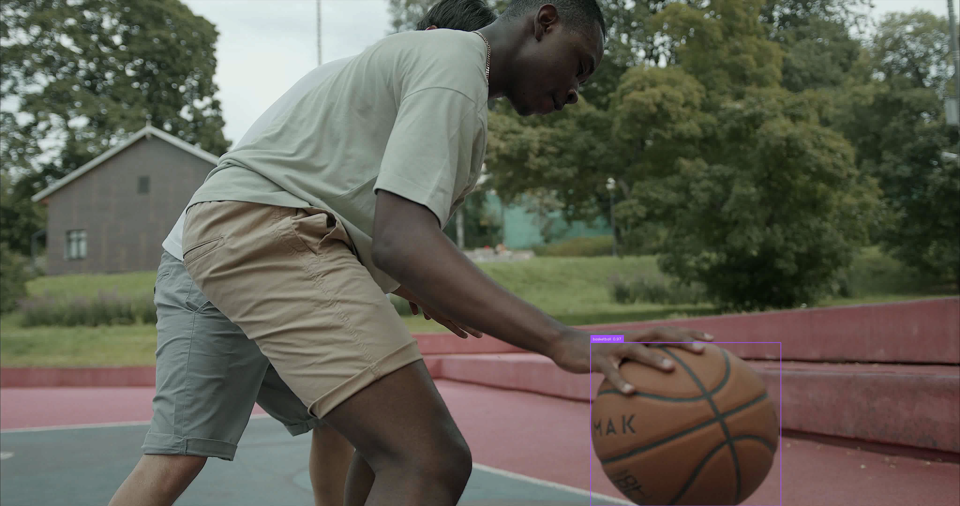

Annotated frame 118


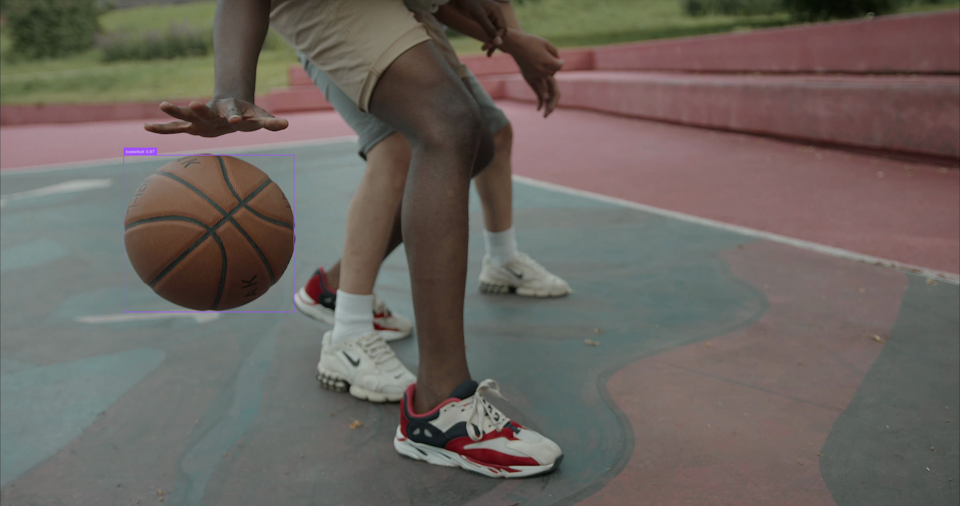

Annotated frame 235


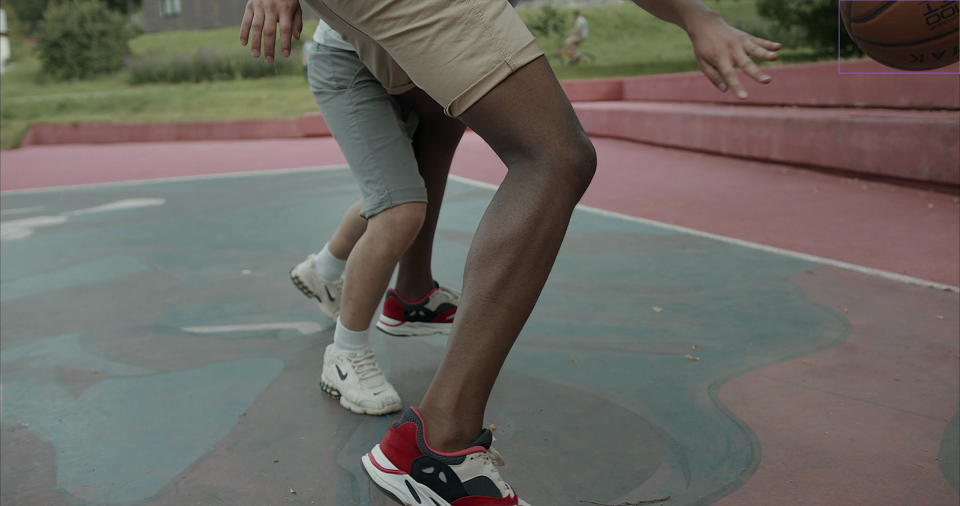

Previews: data/sources/downloads/basketball_videos/basketball_dribbling.webm
Annotated frame 0


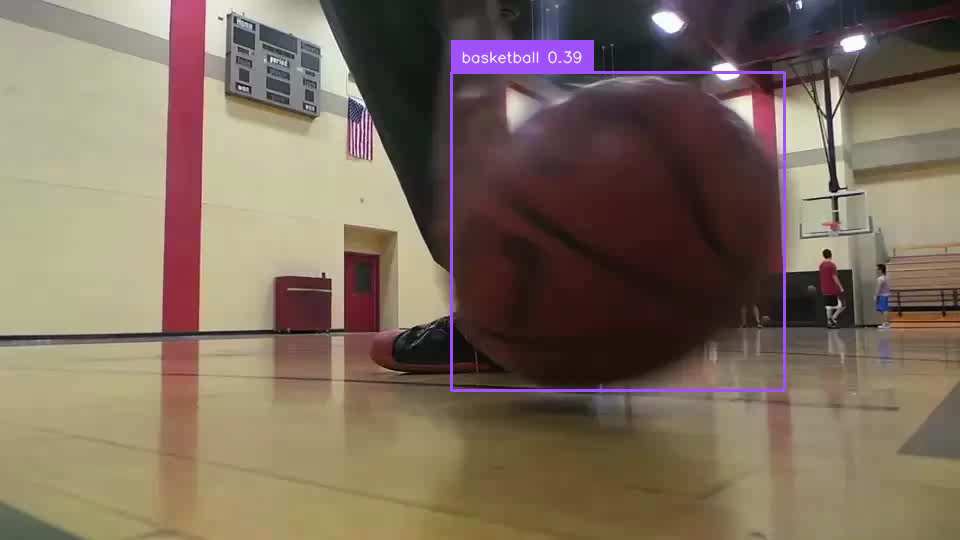

Annotated frame 879


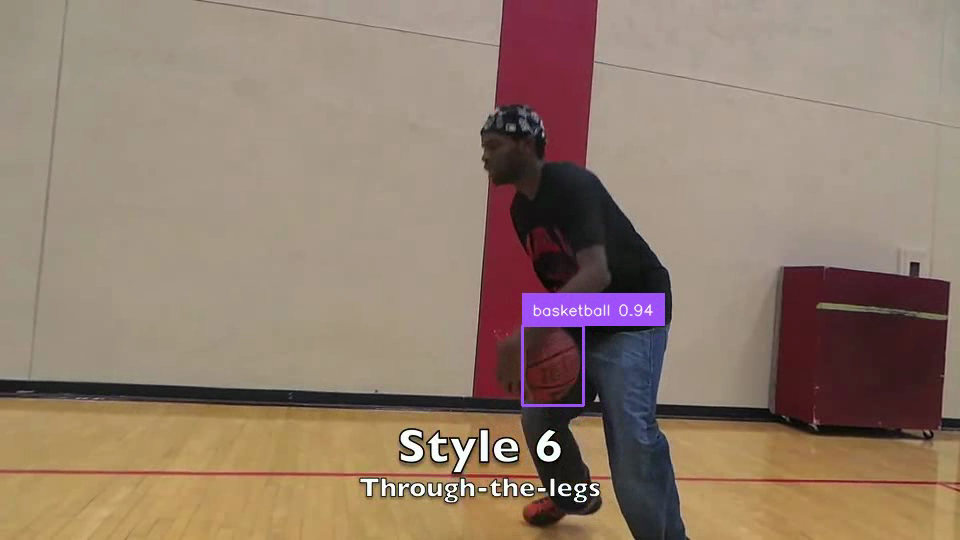

Annotated frame 1757


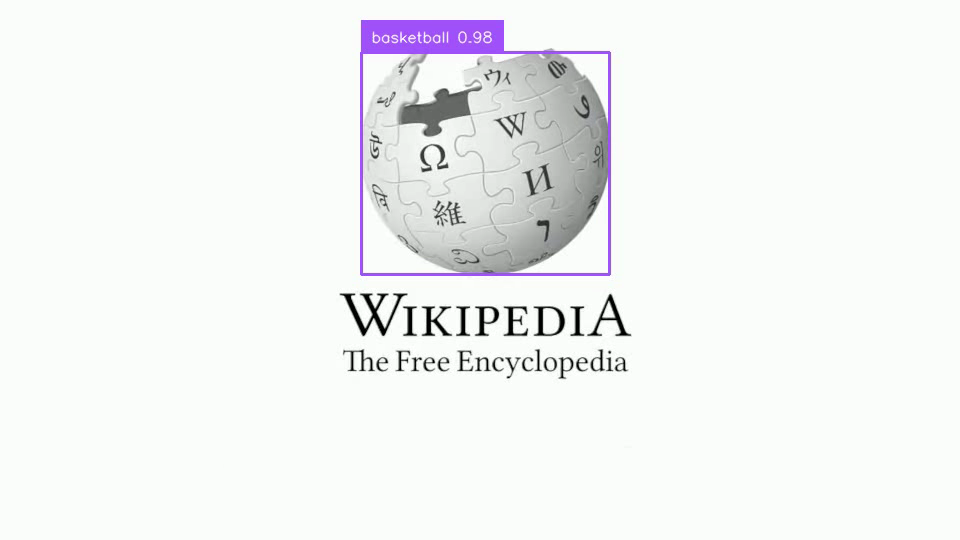

Previews: data/sources/downloads/basketball_videos/basketball-nba_clip.mp4
Annotated frame 0


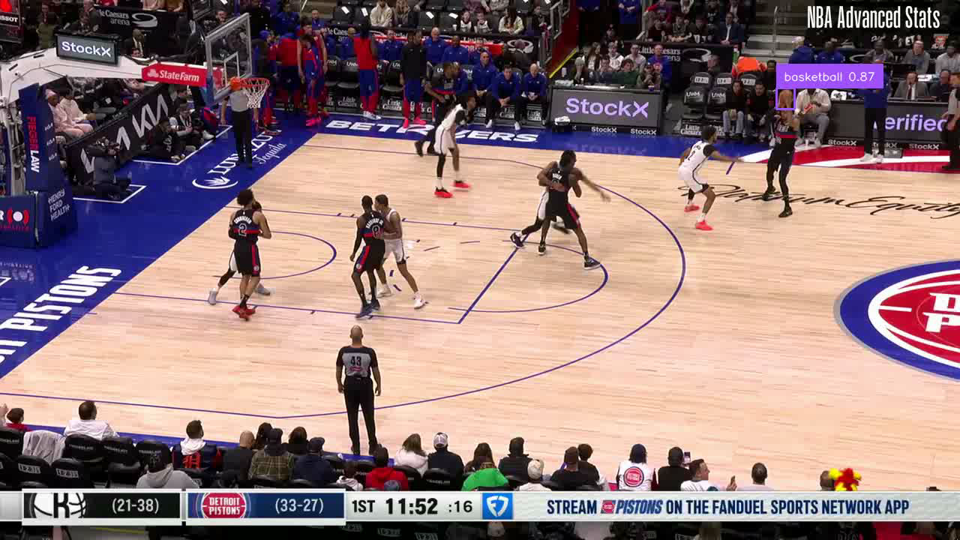

Annotated frame 277


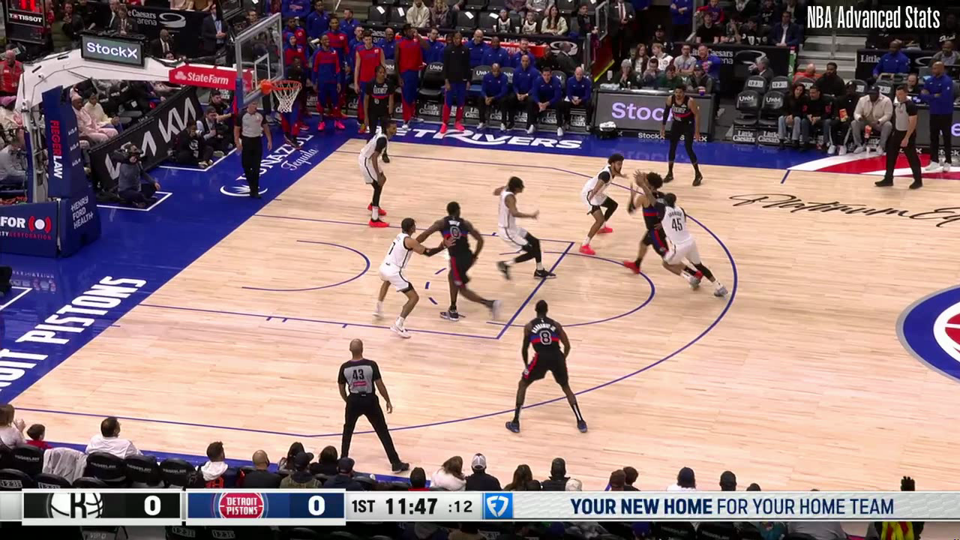

Annotated frame 554


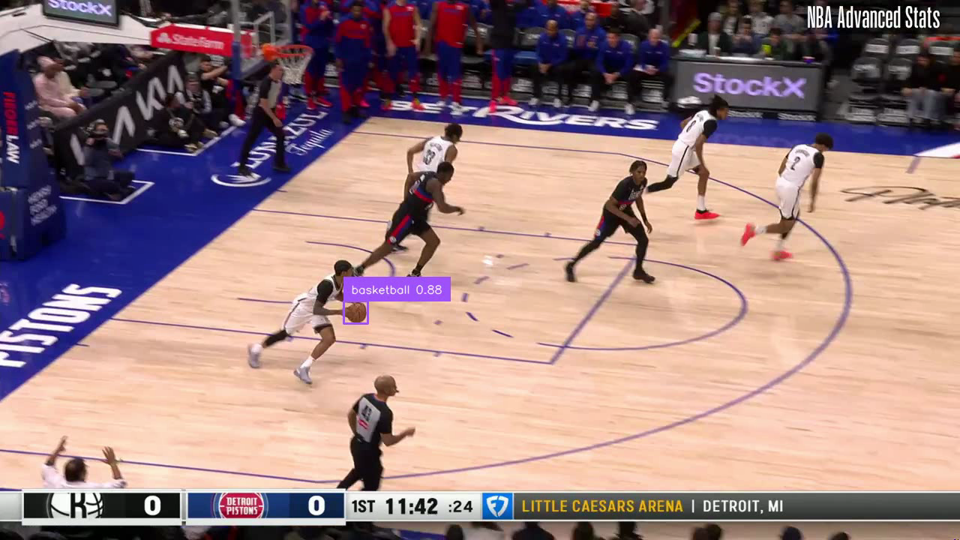

In [8]:
for output_dir in output_dirs:
    summary = read_json(output_dir / "summary.json")
    print(f"Previews: {summary['video_path']}")
    preview_indices = sorted(
        {0, summary["processed_frames"] // 2, max(0, summary["processed_frames"] - 1)}
    )
    capture = cv2.VideoCapture(str(output_dir / "annotated.mp4"))
    try:
        for frame_index in preview_indices:
            capture.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
            readable, frame = capture.read()
            if readable:
                preview = Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
                preview.thumbnail((960, 540))
                print(f"Annotated frame {frame_index}")
                display(preview)
            else:
                print(
                    f"Preview unavailable at frame {frame_index}; "
                    "inspect the MP4 manually"
                )
    finally:
        capture.release()